In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Libraries imported successfully!")

Pandas: 2.3.3
NumPy: 2.3.5
Libraries imported successfully!


In [3]:
from getpass import getpass
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus
import pandas as pd

host = "127.0.0.1"
port = 3306
database = "foodflow_analytics"
username = "root"

password = getpass("Enter your MySQL password: ")

connection_url = (
    f"mysql+pymysql://{quote_plus(username)}:"
    f"{quote_plus(password)}@{host}:{port}/{database}"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("Connected database:", connection.execute(
        text("SELECT DATABASE()")
    ).scalar())

    df_test = pd.read_sql(
        text("SELECT * FROM orders LIMIT 5"),
        connection
    )

display(df_test)

Connected database: foodflow_analytics


,order_id,order_date,order_time,platform,customer_id,restaurant_id,rider_id,order_status,payment_method,item_count,subtotal,discount,delivery_fee,packaging_fee,tax,total_amount,promised_delivery_minutes
0,ORD000001,2025-03-15,0 days 14:34:00,Zomato,CUST17176,REST0519,RID0994,Delivered,UPI,3,744.59,37.23,47.56,22.39,38.87,816.18,41
1,ORD000002,2025-05-24,0 days 13:47:00,Swiggy,CUST04845,REST0514,RID0568,Delivered,Credit Card,1,226.01,11.30,56.47,14.82,14.30,300.30,57
2,ORD000003,2025-06-27,0 days 10:43:00,Zomato,CUST03412,REST0250,RID1941,Delivered,Credit Card,2,485.25,48.53,23.86,20.19,24.04,504.81,39
3,ORD000004,2025-09-15,0 days 12:41:00,Swiggy,CUST04978,REST0033,RID2193,Delivered,UPI,2,304.66,15.23,41.62,13.05,17.21,361.31,42
4,ORD000005,2025-04-19,0 days 10:23:00,Zomato,CUST05887,REST0647,RID0036,Delivered,Credit Card,3,934.08,93.41,55.58,19.79,45.80,961.84,48


In [4]:
# Check the total number of orders
with engine.connect() as connection:
    total_orders = connection.execute(
        text("SELECT COUNT(*) FROM orders")
    ).scalar()

print("Total orders:", total_orders)

# Load orders from MySQL into Pandas
with engine.connect() as connection:
    orders_df = pd.read_sql(
        text("SELECT * FROM orders"),
        connection
    )

print("Dataset shape:", orders_df.shape)
display(orders_df.head())

Total orders: 60000
Dataset shape: (60000, 17)


,order_id,order_date,order_time,platform,customer_id,restaurant_id,rider_id,order_status,payment_method,item_count,subtotal,discount,delivery_fee,packaging_fee,tax,total_amount,promised_delivery_minutes
0,ORD000001,2025-03-15,0 days 14:34:00,Zomato,CUST17176,REST0519,RID0994,Delivered,UPI,3,744.59,37.23,47.56,22.39,38.87,816.18,41
1,ORD000002,2025-05-24,0 days 13:47:00,Swiggy,CUST04845,REST0514,RID0568,Delivered,Credit Card,1,226.01,11.30,56.47,14.82,14.30,300.30,57
2,ORD000003,2025-06-27,0 days 10:43:00,Zomato,CUST03412,REST0250,RID1941,Delivered,Credit Card,2,485.25,48.53,23.86,20.19,24.04,504.81,39
3,ORD000004,2025-09-15,0 days 12:41:00,Swiggy,CUST04978,REST0033,RID2193,Delivered,UPI,2,304.66,15.23,41.62,13.05,17.21,361.31,42
4,ORD000005,2025-04-19,0 days 10:23:00,Zomato,CUST05887,REST0647,RID0036,Delivered,Credit Card,3,934.08,93.41,55.58,19.79,45.80,961.84,48


In [5]:
# Basic dataset information
print("Shape:", orders_df.shape)

print("\nColumn names:")
print(orders_df.columns.tolist())

print("\nData types and non-null counts:")
orders_df.info()

print("\nMissing values per column:")
display(orders_df.isnull().sum())

print("\nDuplicate order IDs:")
print(orders_df["order_id"].duplicated().sum())

print("\nSummary statistics:")
display(orders_df.describe(include="all").T)

Shape: (60000, 17)

Column names:
['order_id', 'order_date', 'order_time', 'platform', 'customer_id', 'restaurant_id', 'rider_id', 'order_status', 'payment_method', 'item_count', 'subtotal', 'discount', 'delivery_fee', 'packaging_fee', 'tax', 'total_amount', 'promised_delivery_minutes']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype          
---  ------                     --------------  -----          
 0   order_id                   60000 non-null  object         
 1   order_date                 60000 non-null  object         
 2   order_time                 60000 non-null  timedelta64[ns]
 3   platform                   60000 non-null  object         
 4   customer_id                60000 non-null  object         
 5   restaurant_id              60000 non-null  object         
 6   rider_id                   60000 non-null  object    

order_id                     0
order_date                   0
order_time                   0
platform                     0
customer_id                  0
restaurant_id                0
rider_id                     0
order_status                 0
payment_method               0
item_count                   0
subtotal                     0
discount                     0
delivery_fee                 0
packaging_fee                0
tax                          0
total_amount                 0
promised_delivery_minutes    0
dtype: int64


Duplicate order IDs:
0

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,60000,60000,ORD000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,60000,365,2025-05-31,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_time,60000,NaN,NaN,NaN,0 days 15:59:58.866000,0 days 04:38:05.647473639,0 days 08:00:00,0 days 11:58:00,0 days 16:02:00,0 days 20:01:00,0 days 23:59:00
platform,60000,2,Zomato,31263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,60000,17297,CUST03167,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restaurant_id,60000,700,REST0218,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rider_id,60000,2200,RID1327,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_status,60000,4,Delivered,54920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,60000,5,UPI,28779,NaN,NaN,NaN,NaN,NaN,NaN,NaN
item_count,60000.0,NaN,NaN,NaN,2.132867,1.112235,1.0,1.0,2.0,3.0,5.0


In [6]:
# 1. Dataset size
print("Rows:", orders_df.shape[0])
print("Columns:", orders_df.shape[1])

# 2. Missing values
missing = orders_df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(orders_df) * 100).round(2)
})

display(missing_report[missing_report["Missing_Count"] > 0])

# 3. Duplicate records
print("Duplicate rows:", orders_df.duplicated().sum())
print("Duplicate order IDs:", orders_df["order_id"].duplicated().sum())

# 4. Data types
display(orders_df.dtypes.to_frame("Data_Type"))

# 5. Check order status values
display(orders_df["order_status"].value_counts(dropna=False))

# 6. Check platform values
display(orders_df["platform"].value_counts(dropna=False))

Rows: 60000
Columns: 17


,Missing_Count,Missing_Percentage


Duplicate rows: 0
Duplicate order IDs: 0


,Data_Type
order_id,object
order_date,object
order_time,timedelta64[ns]
platform,object
customer_id,object
restaurant_id,object
rider_id,object
order_status,object
payment_method,object
item_count,int64


order_status
Delivered          54920
Cancelled           3445
Rejected             998
Failed Delivery      637
Name: count, dtype: int64

platform
Zomato    31263
Swiggy    28737
Name: count, dtype: int64

In [7]:
# Numeric column summary
numeric_cols = [
    "item_count",
    "subtotal",
    "discount",
    "delivery_fee",
    "packaging_fee",
    "tax",
    "total_amount",
    "promised_delivery_minutes"
]

display(orders_df[numeric_cols].describe().T)

# Check impossible or suspicious values
print("Non-positive item counts:",
      (orders_df["item_count"] <= 0).sum())

print("Negative subtotals:",
      (orders_df["subtotal"] < 0).sum())

print("Negative discounts:",
      (orders_df["discount"] < 0).sum())

print("Negative total amounts:",
      (orders_df["total_amount"] < 0).sum())

print("Non-positive promised delivery times:",
      (orders_df["promised_delivery_minutes"] <= 0).sum())

,count,mean,std,min,25%,50%,75%,max
item_count,60000.0,2.132867,1.112235,1.00,1.00,2.000,3.0000,5.00
subtotal,60000.0,447.859891,281.306861,70.00,237.00,370.875,589.6825,1666.07
discount,60000.0,26.822839,37.765641,0.00,0.00,13.180,39.5600,319.38
delivery_fee,60000.0,36.582506,16.246031,15.00,22.01,28.970,51.5400,97.69
packaging_fee,60000.0,17.509277,7.208093,5.00,11.29,17.490,23.7600,30.00
tax,60000.0,23.756514,13.354587,4.14,13.77,20.150,30.4400,85.38
total_amount,60000.0,498.885348,280.446410,86.85,289.18,423.195,639.1525,1792.96
promised_delivery_minutes,60000.0,45.813333,6.525465,24.00,41.00,45.000,50.0000,65.00


Non-positive item counts: 0
Negative subtotals: 0
Negative discounts: 0
Negative total amounts: 0
Non-positive promised delivery times: 0


In [9]:
orders_df.columns

Index(['order_id', 'order_date', 'order_time', 'platform', 'customer_id',
       'restaurant_id', 'rider_id', 'order_status', 'payment_method',
       'item_count', 'subtotal', 'discount', 'delivery_fee', 'packaging_fee',
       'tax', 'total_amount', 'promised_delivery_minutes'],
      dtype='object')

In [11]:
orders_df.describe()

,order_time,item_count,subtotal,discount,delivery_fee,packaging_fee,tax,total_amount,promised_delivery_minutes
count,60000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000
mean,0 days 15:59:58.866000,2.132867,447.859891,26.822839,36.582506,17.509277,23.756514,498.885348,45.813333
std,0 days 04:38:05.647473639,1.112235,281.306861,37.765641,16.246031,7.208093,13.354587,280.446410,6.525465
min,0 days 08:00:00,1.000000,70.000000,0.000000,15.000000,5.000000,4.140000,86.850000,24.000000
25%,0 days 11:58:00,1.000000,237.000000,0.000000,22.010000,11.290000,13.770000,289.180000,41.000000
50%,0 days 16:02:00,2.000000,370.875000,13.180000,28.970000,17.490000,20.150000,423.195000,45.000000
75%,0 days 20:01:00,3.000000,589.682500,39.560000,51.540000,23.760000,30.440000,639.152500,50.000000
max,0 days 23:59:00,5.000000,1666.070000,319.380000,97.690000,30.000000,85.380000,1792.960000,65.000000


Step 9 — Clean and validate the orders data

In [16]:
# Check duplicate order IDs
orders_df["order_id"].duplicated().sum()




np.int64(0)

In [14]:
#Check missing values
orders_df.isnull().sum()

order_id                     0
order_date                   0
order_time                   0
platform                     0
customer_id                  0
restaurant_id                0
rider_id                     0
order_status                 0
payment_method               0
item_count                   0
subtotal                     0
discount                     0
delivery_fee                 0
packaging_fee                0
tax                          0
total_amount                 0
promised_delivery_minutes    0
dtype: int64

In [15]:
# Check and convert data types
orders_df.dtypes

order_id                              object
order_date                    datetime64[ns]
order_time                   timedelta64[ns]
platform                              object
customer_id                           object
restaurant_id                         object
rider_id                              object
order_status                          object
payment_method                        object
item_count                             int64
subtotal                             float64
discount                             float64
delivery_fee                         float64
packaging_fee                        float64
tax                                  float64
total_amount                         float64
promised_delivery_minutes              int64
dtype: object

In [ ]:
#Convert the date and time columns if needed:

orders_df["order_date"] = pd.to_datetime(
    orders_df["order_date"], errors="coerce"
)

orders_df["order_time"] = pd.to_timedelta(
    orders_df["order_time"].astype(str),
    errors="coerce"
)

In [18]:
#Check invalid values
orders_df[orders_df["item_count"] <= 0]

,order_id,order_date,order_time,platform,customer_id,restaurant_id,rider_id,order_status,payment_method,item_count,subtotal,discount,delivery_fee,packaging_fee,tax,total_amount,promised_delivery_minutes


In [20]:
orders_df[orders_df["total_amount"] < 0]

,order_id,order_date,order_time,platform,customer_id,restaurant_id,rider_id,order_status,payment_method,item_count,subtotal,discount,delivery_fee,packaging_fee,tax,total_amount,promised_delivery_minutes


In [21]:
orders_df[orders_df["promised_delivery_minutes"] <= 0]

,order_id,order_date,order_time,platform,customer_id,restaurant_id,rider_id,order_status,payment_method,item_count,subtotal,discount,delivery_fee,packaging_fee,tax,total_amount,promised_delivery_minutes


Step 10 — Create useful analysis columns

In [22]:
# 10.1 Extract year and month

orders_df["year"] = orders_df["order_date"].dt.year
orders_df["month"] = orders_df["order_date"].dt.month
orders_df["month_name"] = orders_df["order_date"].dt.month_name()
orders_df["day_name"] = orders_df["order_date"].dt.day_name()

In [24]:
orders_df["day_name"]

0         Saturday
1         Saturday
2           Friday
3           Monday
4         Saturday
           ...    
59995    Wednesday
59996       Monday
59997       Sunday
59998       Monday
59999    Wednesday
Name: day_name, Length: 60000, dtype: object

In [25]:
# 10.2 Extract the order hour

orders_df["order_hour"] = (
    orders_df["order_time"].dt.total_seconds() // 3600
).astype("Int64")

In [28]:
# Categorize meal periods

orders_df["meal_period"] = pd.cut(
    orders_df["order_hour"],
    bins=[-1, 10, 15, 18, 23],
    labels=["Breakfast", "Lunch", "Snacks", "Dinner"]
)

In [ ]:
#Preview the new columns

orders_df[
    ["order_date", "order_time", "year", "month_name",
     "day_name", "order_hour", "meal_period"]
].head()

,order_date,order_time,year,month_name,day_name,order_hour,meal_period
0,2025-03-15,0 days 14:34:00,2025,March,Saturday,14,Lunch
1,2025-05-24,0 days 13:47:00,2025,May,Saturday,13,Lunch
2,2025-06-27,0 days 10:43:00,2025,June,Friday,10,Breakfast
3,2025-09-15,0 days 12:41:00,2025,September,Monday,12,Lunch
4,2025-04-19,0 days 10:23:00,2025,April,Saturday,10,Breakfast


In [29]:
orders_df.shape

(60000, 23)

In [30]:
orders_df[["year", "month", "month_name", "order_hour", "meal_period"]].head()

,year,month,month_name,order_hour,meal_period
0,2025,3,March,14,Lunch
1,2025,5,May,13,Lunch
2,2025,6,June,10,Breakfast
3,2025,9,September,12,Lunch
4,2025,4,April,10,Breakfast


Step 12 — Overall business KPIs

In [32]:
# Overall order KPIs

total_orders = len(orders_df)

delivered_orders = (orders_df["order_status"] == "Delivered").sum()

cancelled_orders = (orders_df["order_status"] == "Cancelled").sum()

rejected_orders = (orders_df["order_status"] == "Rejected").sum()

failed_orders = (orders_df["order_status"] == "Failed Delivery").sum()

delivered_revenue = orders_df.loc[
    orders_df["order_status"] == "Delivered", "total_amount"
].sum()

average_order_value = (
    delivered_revenue / delivered_orders if delivered_orders else 0
)

delivery_success_rate = (
    delivered_orders / total_orders * 100 if total_orders else 0
)

print("Total Orders:", total_orders)
print("Delivered Orders:", delivered_orders)
print("Cancelled Orders:", cancelled_orders)
print("Rejected Orders:", rejected_orders)
print("Failed Delivery Orders:", failed_orders)
print("Delivered Revenue:", round(delivered_revenue, 2))
print("Average Delivered Order Value:", round(average_order_value, 2))
print("Delivery Success Rate:", round(delivery_success_rate, 2), "%")

Total Orders: 60000
Delivered Orders: 54920
Cancelled Orders: 3445
Rejected Orders: 998
Failed Delivery Orders: 637
Delivered Revenue: 27406996.77
Average Delivered Order Value: 499.03
Delivery Success Rate: 91.53 %


Step 13 — Compare Zomato and Swiggy

In [33]:
platform_analysis = (
    orders_df.groupby("platform")
    .agg(
        total_orders=("order_id", "count"),
        delivered_orders=("order_status", lambda x: (x == "Delivered").sum()),
        cancelled_orders=("order_status", lambda x: (x == "Cancelled").sum()),
        total_revenue=("total_amount", lambda x: x[
            orders_df.loc[x.index, "order_status"] == "Delivered"
        ].sum())
    )
)

platform_analysis["delivery_success_rate_%"] = (
    platform_analysis["delivered_orders"]
    / platform_analysis["total_orders"] * 100
).round(2)

platform_analysis["average_delivered_order_value"] = (
    platform_analysis["total_revenue"]
    / platform_analysis["delivered_orders"]
).round(2)

platform_analysis

,total_orders,delivered_orders,cancelled_orders,total_revenue,delivery_success_rate_%,average_delivered_order_value
platform,,,,,,
Swiggy,28737,26264,1678,13120682.73,91.39,499.57
Zomato,31263,28656,1767,14286314.04,91.66,498.55


Step 14 — Monthly revenue trends

In [34]:
monthly_analysis = (
    orders_df[orders_df["order_status"] == "Delivered"]
    .groupby(["year", "month", "month_name"])
    .agg(
        orders=("order_id", "count"),
        revenue=("total_amount", "sum"),
        average_order_value=("total_amount", "mean")
    )
    .round(2)
    .reset_index()
)

monthly_analysis

,year,month,month_name,orders,revenue,average_order_value
0,2025,1,January,4600,2296469.85,499.23
1,2025,2,February,4138,2037504.74,492.39
2,2025,3,March,4798,2418619.62,504.09
3,2025,4,April,4573,2285337.12,499.75
4,2025,5,May,4748,2364302.25,497.96
5,2025,6,June,4552,2266717.06,497.96
6,2025,7,July,4610,2297736.43,498.42
7,2025,8,August,4677,2337239.68,499.73
8,2025,9,September,4472,2238259.39,500.51
9,2025,10,October,4607,2318024.09,503.15


Step 15 — Visualize monthly revenue

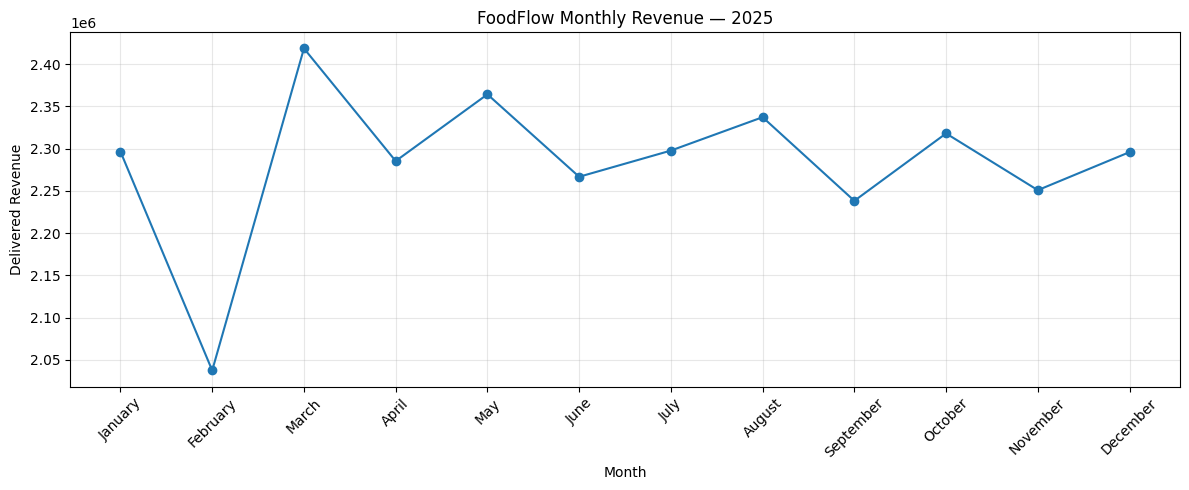

In [35]:
import matplotlib.pyplot as plt

monthly_analysis = monthly_analysis.sort_values(["year", "month"])

plt.figure(figsize=(12, 5))
plt.plot(monthly_analysis["month_name"], monthly_analysis["revenue"], marker="o")
plt.title("FoodFlow Monthly Revenue — 2025")
plt.xlabel("Month")
plt.ylabel("Delivered Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Step 20 — Delivery and cancellation analysis

In [36]:
# Load delivery and cancellation tables from MySQL
with engine.connect() as connection:
    delivery_df = pd.read_sql("SELECT * FROM delivery", connection)
    cancellations_df = pd.read_sql(
        "SELECT * FROM cancellations", connection
    )

print("Delivery data:", delivery_df.shape)
print("Cancellation data:", cancellations_df.shape)

# Delivery performance
delivery_df.describe()

# Late delivery rate
print(
    "Late delivery rate (%):",
    round(delivery_df["late_delivery"].mean() * 100, 2)
)

# Average actual delivery time
print(
    "Average actual delivery time (minutes):",
    round(delivery_df["actual_delivery_minutes"].mean(), 2)
)

# Average delivery time by traffic level
delivery_df.groupby("traffic_level")[
    "actual_delivery_minutes"
].mean().sort_values(ascending=False)

Delivery data: (60000, 11)
Cancellation data: (4443, 8)
Late delivery rate (%): 35.88
Average actual delivery time (minutes): 43.43


traffic_level
High      52.164121
Medium    45.104123
Low       40.643176
Name: actual_delivery_minutes, dtype: float64

analyze cancellation reasons:

In [37]:
# Cancellation reasons
cancellations_df["cancellation_reason"].value_counts()

# Cancellation stage
cancellations_df["cancellation_stage"].value_counts()

# Total refund amount
print("Total refunds:", cancellations_df["refund_amount"].sum())

# Total food waste cost
print("Total food waste cost:", cancellations_df["food_waste_cost"].sum())

# Cancellation count by who cancelled
cancellations_df["cancelled_by"].value_counts()

Total refunds: 1930849.5299999998
Total food waste cost: 477130.02


cancelled_by
Customer      2509
Restaurant    1092
Rider          595
Platform       247
Name: count, dtype: int64

In [38]:
from pathlib import Path
import matplotlib.pyplot as plt

visualization_dir = Path("visualizations")
visualization_dir.mkdir(parents=True, exist_ok=True)

Monthly revenue

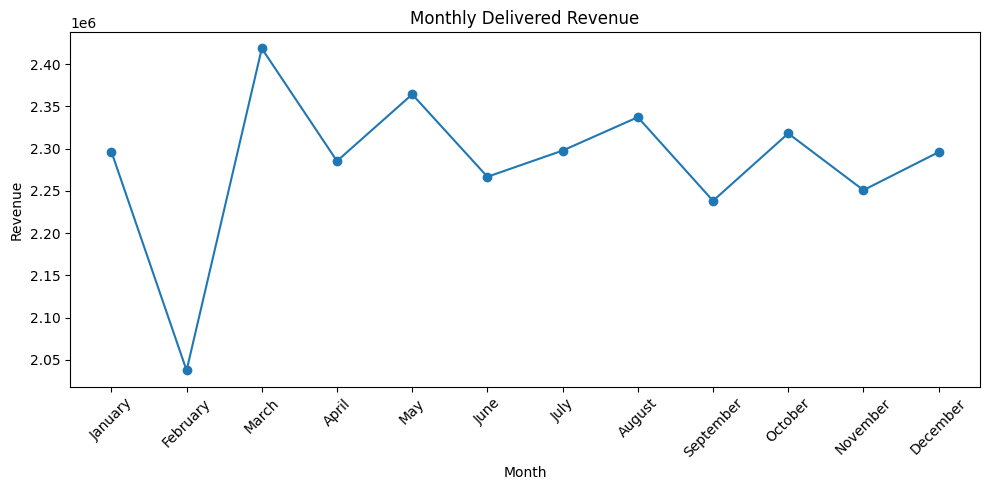

In [39]:
monthly_analysis = monthly_analysis.sort_values(["year", "month"])

plt.figure(figsize=(10, 5))
plt.plot(monthly_analysis["month_name"], monthly_analysis["revenue"], marker="o")
plt.title("Monthly Delivered Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(visualization_dir / "monthly_revenue.png", dpi=150)
plt.show()

Revenue by platform

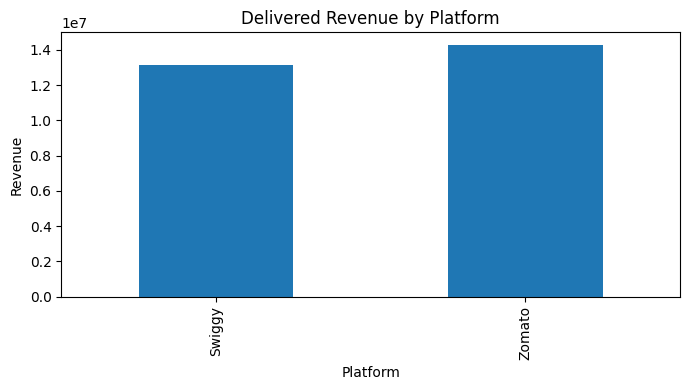

In [40]:
platform_analysis["total_revenue"].plot(kind="bar", figsize=(7, 4))
plt.title("Delivered Revenue by Platform")
plt.xlabel("Platform")
plt.ylabel("Revenue")
plt.tight_layout()
plt.savefig(visualization_dir / "platform_revenue.png", dpi=150)
plt.show()

Cancellation reason

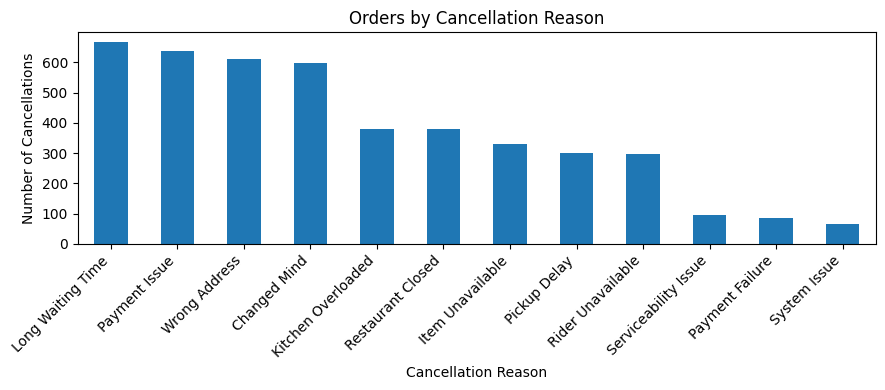

In [41]:
cancellations_df["cancellation_reason"].value_counts().plot(
    kind="bar", figsize=(9, 4)
)

plt.title("Orders by Cancellation Reason")
plt.xlabel("Cancellation Reason")
plt.ylabel("Number of Cancellations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(visualization_dir / "cancellation_reasons.png", dpi=150)
plt.show()

Average delivery time by traffic

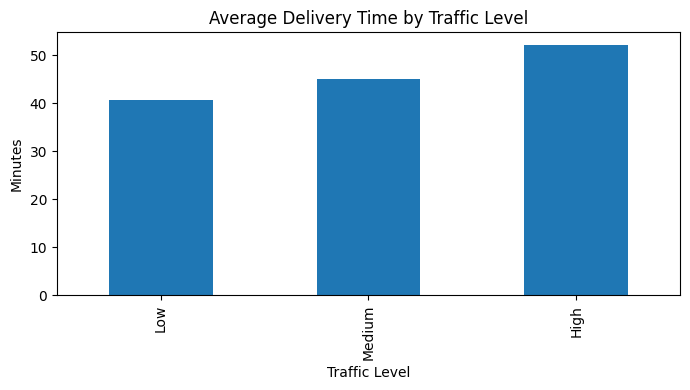

In [42]:
delivery_df.groupby("traffic_level")[
    "actual_delivery_minutes"
].mean().sort_values().plot(kind="bar", figsize=(7, 4))

plt.title("Average Delivery Time by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Minutes")
plt.tight_layout()
plt.savefig(visualization_dir / "delivery_by_traffic.png", dpi=150)
plt.show()